In [37]:
import numpy as np
import matplotlib.pyplot as plt

In [38]:
# Toy geodesic derivative: dr/dtau = -sqrt(1/r)
def dr_dtau(r):
    return -np.sqrt(1.0 / r)

# Exact solution for dr/dtau = -r^(-1/2) starting at r0=10.0, evaluated at tau=10.0
# Integral: (2/3)*(r0^(3/2) - r^(3/2)) = tau

In [39]:
tau_target = 10.0
r0 = 10.0
r_exact = (r0**(1.5) - 1.5 * tau_target)**(2/3)

dtau_list = np.array([0.5, 0.25, 0.1, 0.05, 0.025, 0.01])

errors_euler = []
errors_rk2 = []
errors_rk4 = []

for dtau in dtau_list:
    n_steps = int(tau_target / dtau)
    
    # 1. First-Order (Euler)
    r = r0
    for _ in range(n_steps):
        r += dtau * dr_dtau(r)
    errors_euler.append(abs(r - r_exact))
    
    # 2. Second-Order (RK2 / Midpoint)
    r = r0
    for _ in range(n_steps):
        k1 = dr_dtau(r)
        k2 = dr_dtau(r + 0.5 * dtau * k1)
        r += dtau * k2
    errors_rk2.append(abs(r - r_exact))
    
    # 3. Fourth-Order (RK4)
    r = r0
    for _ in range(n_steps):
        k1 = dr_dtau(r)
        k2 = dr_dtau(r + 0.5 * dtau * k1)
        k3 = dr_dtau(r + 0.5 * dtau * k2)
        k4 = dr_dtau(r + dtau * k3)
        r += (dtau / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    errors_rk4.append(abs(r - r_exact))

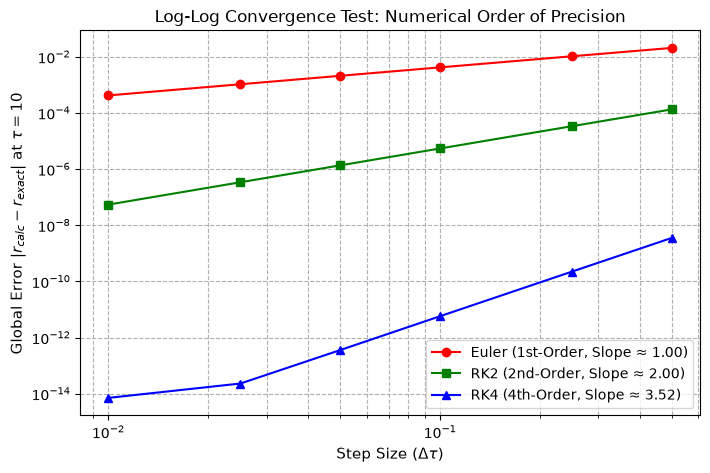

In [40]:
# Calculating slopes on log-log scale (Order of Accuracy p)
slope_euler, _ = np.polyfit(np.log(dtau_list), np.log(errors_euler), 1)
slope_rk2, _ = np.polyfit(np.log(dtau_list), np.log(errors_rk2), 1)
slope_rk4, _ = np.polyfit(np.log(dtau_list), np.log(errors_rk4), 1)

# log-log Convergence plot
plt.figure(figsize=(8, 5))
plt.loglog(dtau_list, errors_euler, 'r-o', label=f'Euler (1st-Order, Slope ≈ {slope_euler:.2f})')
plt.loglog(dtau_list, errors_rk2, 'g-s', label=f'RK2 (2nd-Order, Slope ≈ {slope_rk2:.2f})')
plt.loglog(dtau_list, errors_rk4, 'b-^', label=f'RK4 (4th-Order, Slope ≈ {slope_rk4:.2f})')

plt.xlabel(r'Step Size ($\Delta\tau$)', fontsize=11)
plt.ylabel(r'Global Error $|r_{calc} - r_{exact}|$ at $\tau=10$', fontsize=11)
plt.title('Log-Log Convergence Test: Numerical Order of Precision', fontsize=12)
plt.grid(True, which="both", linestyle="--")
plt.legend(fontsize=10)
plt.show()

# Comparison of the main work:

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# 1. PHYSICAL INPUTS (Measurable Quantities)
M = 1.0
a = 0.95
L = 2.0  # Specific Angular Momentum
r_initial = 10.0  # Starting radial distance
tau_initial = 0.0
horizon = 1.0 + np.sqrt(1.0 - a**2)

# 2. CALCULATING SPECIFIC ENERGY (E) FROM REST
alpha = r_initial**3 + (a**2)*r_initial + 2*M*(a**2)
beta = -4*a*M*L
gamma = -(L**2)*(r_initial - 2*M) - r_initial*(r_initial**2 - 2*M*r_initial + a**2)

discriminant = beta**2 - 4*alpha*gamma
if discriminant < 0:
    raise ValueError(f"No physical orbit exists for L={L} starting from rest at r={r_initial}.")

E = (-beta + np.sqrt(discriminant)) / (2 * alpha)
print(f"Calculated Specific Energy (E): {E:.6f}")

Calculated Specific Energy (E): 0.915915


In [42]:
def Sigma(r):
    return r**2 - 2*M*r + a**2

def R_eff(r):
    term1 = (E**2) * (r**3 + (a**2)*r + 2*M*(a**2))
    term2 = -4 * a * M * E * L
    term3 = -(L**2) * (r - 2*M)
    term4 = -r * Sigma(r)
    return term1 + term2 + term3 + term4

def dr_dtau(r):
    R_val = R_eff(r)
    if R_val <= 0:  # Failsafe for unphysical/turning points
        return 0.0
    return -np.sqrt(R_val / (r**3))

In [49]:
def run_solver(method='rk4', dtau=0.1, max_steps=100000):
    tau_vals = [tau_initial]
    r_vals = [r_initial]
    
    r_current = r_initial - 1e-7  # Microscopic nudge to initiate inward motion
    tau_current = tau_initial
    step = 0
    
    while r_current > horizon and step < max_steps:
        if method == 'euler':
            # 1st-Order Euler Method
            k1 = dr_dtau(r_current)
            r_next = r_current + dtau * k1
            
        elif method == 'rk2':
            # 2nd-Order RK2 (Midpoint) Method
            k1 = dr_dtau(r_current)
            k2 = dr_dtau(r_current + 0.5 * dtau * k1)
            r_next = r_current + dtau * k2
            
        elif method == 'rk4':
            # 4th-Order RK4 Method
            k1 = dr_dtau(r_current)
            k2 = dr_dtau(r_current + 0.5 * dtau * k1)
            k3 = dr_dtau(r_current + 0.5 * dtau * k2)
            k4 = dr_dtau(r_current + dtau * k3)
            r_next = r_current + (dtau / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
        
        r_current = r_next
        tau_current += dtau
        
        tau_vals.append(tau_current)
        r_vals.append(r_current)
        step += 1
        
    return np.array(tau_vals), np.array(r_vals)

# Running all three methods at dtau = 0.01 (or some other step size)
tau_euler, r_euler = run_solver(method='euler', dtau=0.1)
tau_rk2, r_rk2     = run_solver(method='rk2', dtau=0.1)
tau_rk4, r_rk4     = run_solver(method='rk4', dtau=0.1)

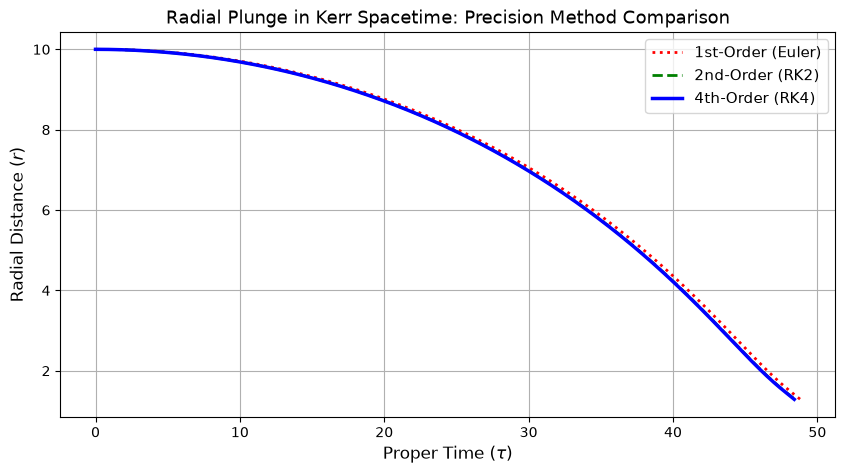

In [50]:
plt.figure(figsize=(10, 5))
plt.plot(tau_euler, r_euler, 'r:', linewidth=2, label='1st-Order (Euler)')
plt.plot(tau_rk2, r_rk2, 'g--', linewidth=2, label='2nd-Order (RK2)')
plt.plot(tau_rk4, r_rk4, 'b-', linewidth=2.5, label='4th-Order (RK4)')

plt.title("Radial Plunge in Kerr Spacetime: Precision Method Comparison", fontsize=13)
plt.xlabel(r"Proper Time ($\tau$)", fontsize=12)
plt.ylabel(r"Radial Distance ($r$)", fontsize=12)
plt.grid(True)
plt.legend(fontsize=11)
plt.show()

##### For this plot above, the difference is more notable if the step size is increased

## An alternate approach:

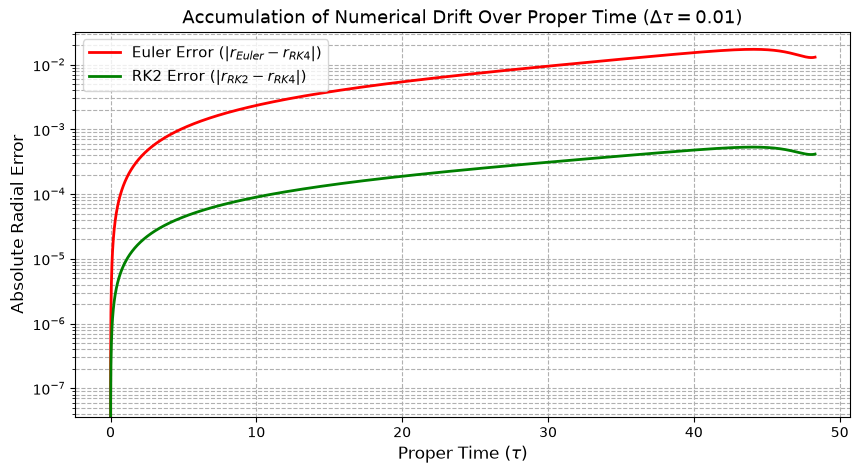

In [45]:
# Run at standard high precision
tau_euler, r_euler = run_solver(method='euler', dtau=0.01)
tau_rk2, r_rk2     = run_solver(method='rk2', dtau=0.01)
tau_rk4, r_rk4     = run_solver(method='rk4', dtau=0.01)

# Find minimum shared length before horizon cutoff
min_len = min(len(r_euler), len(r_rk2), len(r_rk4))

# Slice arrays to equal length and calculate absolute error
tau_common  = tau_rk4[:min_len]
error_euler = np.abs(r_euler[:min_len] - r_rk4[:min_len])
error_rk2   = np.abs(r_rk2[:min_len]   - r_rk4[:min_len])

plt.figure(figsize=(10, 5))
plt.plot(tau_common, error_euler, 'r-', linewidth=2, label=r'Euler Error ($|r_{Euler} - r_{RK4}|$)')
plt.plot(tau_common, error_rk2, 'g-', linewidth=2, label=r'RK2 Error ($|r_{RK2} - r_{RK4}|$)')

plt.title(r"Accumulation of Numerical Drift Over Proper Time ($\Delta\tau = 0.01$)", fontsize=13)
plt.xlabel(r"Proper Time ($\tau$)", fontsize=12)
plt.ylabel("Absolute Radial Error", fontsize=12)
plt.yscale('log')  # Log scale highlights the multi-order magnitude gap in drift
plt.grid(True, which="both", linestyle="--")
plt.legend(fontsize=11)
plt.show()

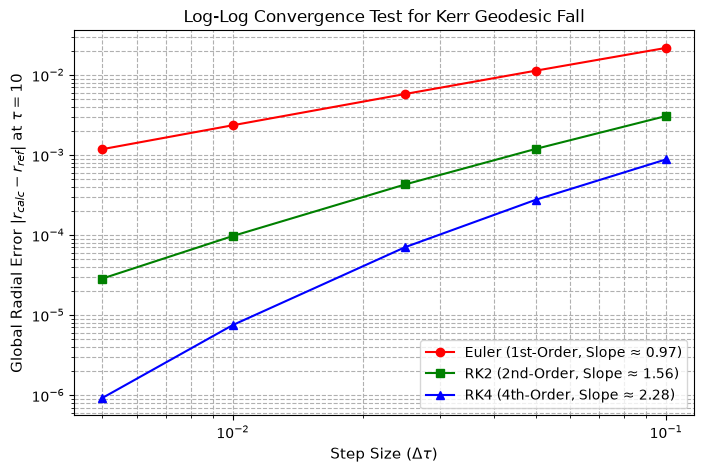

In [46]:
# Reference high-precision trajectory evaluated at fixed target time
tau_target = 10.0
_, r_ref_array = run_solver(method='rk4', dtau=0.0001)
r_exact = r_ref_array[int(tau_target / 0.0001)]

dtau_list = np.array([0.1, 0.05, 0.025, 0.01, 0.005])

errors_euler = []
errors_rk2 = []
errors_rk4 = []

for dt in dtau_list:
    _, r_e = run_solver(method='euler', dtau=dt)
    _, r_2 = run_solver(method='rk2', dtau=dt)
    _, r_4 = run_solver(method='rk4', dtau=dt)
    
    idx = int(tau_target / dt)
    errors_euler.append(abs(r_e[idx] - r_exact))
    errors_rk2.append(abs(r_2[idx] - r_exact))
    errors_rk4.append(abs(r_4[idx] - r_exact))

# slopes on log-log scale
slope_euler, _ = np.polyfit(np.log(dtau_list), np.log(errors_euler), 1)
slope_rk2, _   = np.polyfit(np.log(dtau_list), np.log(errors_rk2), 1)
slope_rk4, _   = np.polyfit(np.log(dtau_list), np.log(errors_rk4), 1)

# Log-Log Plot
plt.figure(figsize=(8, 5))
plt.loglog(dtau_list, errors_euler, 'r-o', label=f'Euler (1st-Order, Slope ≈ {slope_euler:.2f})')
plt.loglog(dtau_list, errors_rk2, 'g-s', label=f'RK2 (2nd-Order, Slope ≈ {slope_rk2:.2f})')
plt.loglog(dtau_list, errors_rk4, 'b-^', label=f'RK4 (4th-Order, Slope ≈ {slope_rk4:.2f})')

plt.xlabel(r'Step Size ($\Delta\tau$)', fontsize=11)
plt.ylabel(r'Global Radial Error $|r_{calc} - r_{ref}|$ at $\tau=10$', fontsize=11)
plt.title('Log-Log Convergence Test for Kerr Geodesic Fall', fontsize=12)
plt.grid(True, which="both", linestyle="--")
plt.legend(fontsize=10)
plt.show()